# Ames Housing: price prediction (midterm project)

I want to estimate the sale price of a house in Ames, Iowa, from its characteristics.
A reliable estimate helps buyers, sellers and agents price a house more objectively.

The data is in `data/AmesHousing.csv` (1,460 rows, 79 features). The target is
`SalePrice` in USD.

I train on `log1p(SalePrice)` and report the RMSE in log space and in dollars.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
print("pandas", pd.__version__)

pandas 3.0.6


## 1. Load the data

In [2]:
df = pd.read_csv("data/AmesHousing.csv")
print("shape:", df.shape)
df[["Id", "SalePrice", "OverallQual", "GrLivArea", "Neighborhood"]].head()

shape: (1460, 81)


,Id,SalePrice,OverallQual,GrLivArea,Neighborhood
0,1,208500,7,1710,CollgCr
1,2,181500,6,1262,Veenker
2,3,223500,7,1786,CollgCr
3,4,140000,7,1717,Crawfor
4,5,250000,8,2198,NoRidge


## 2. Data quality: dtypes and missing values

In [3]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"numeric: {len(num_cols)} | categorical: {len(cat_cols)}")

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"columns with missing values: {len(missing)}")
missing.to_frame("missing")

numeric: 38 | categorical: 43
columns with missing values: 19


,missing
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


## 3. Target variable

`SalePrice` is right skewed. I model `log1p(SalePrice)`, which is close to normal and
stabilises the variance.


count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
skew (raw): 1.883
skew (log1p): 0.121


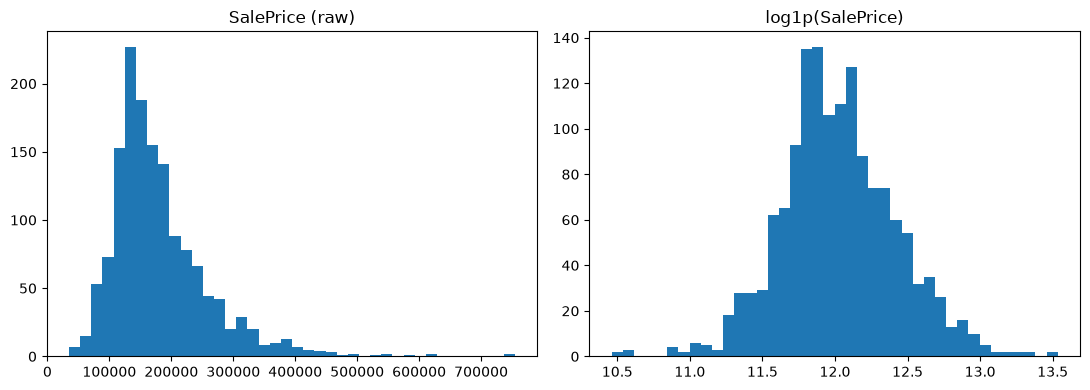

In [4]:
print(df["SalePrice"].describe().round(0))
print("skew (raw):", round(df["SalePrice"].skew(), 3))
print("skew (log1p):", round(np.log1p(df["SalePrice"]).skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["SalePrice"], bins=40)
axes[0].set_title("SalePrice (raw)")
axes[1].hist(np.log1p(df["SalePrice"]), bins=40)
axes[1].set_title("log1p(SalePrice)")
plt.tight_layout()
plt.show()

## 4. Feature importance (correlation with the target)

Numeric correlations give a first view of the strongest signals.

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
GarageYrBlt     0.486
MasVnrArea      0.477
Name: SalePrice, dtype: float64


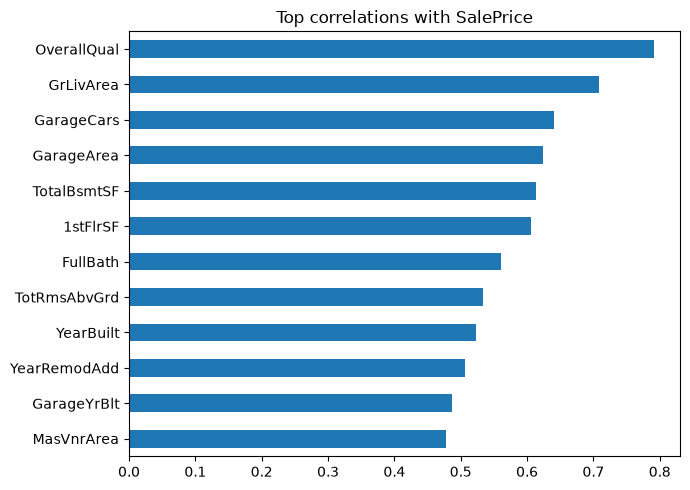

In [5]:
corr = df[num_cols].corr()["SalePrice"].drop(["SalePrice", "Id"])
top = corr.abs().sort_values(ascending=False).head(12)
print(corr.loc[top.index].round(3))

top.sort_values().plot(kind="barh", figsize=(7, 5), title="Top correlations with SalePrice")
plt.tight_layout()
plt.show()

## 5. Preprocessing

- Numeric: median imputation + standardisation
- Categorical: fill with `NA` + one-hot encoding (`handle_unknown='ignore'`)

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data/AmesHousing.csv")
X = df.drop(columns=["SalePrice", "Id"])
y = np.log1p(df["SalePrice"])

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="NA")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
])
print("numeric:", len(num_cols), "| categorical:", len(cat_cols))

numeric: 36 | categorical: 43


## 6. Model selection and tuning

I compare a linear model (Ridge) with two tree ensembles (Random Forest and Gradient
Boosting) and tune the main hyperparameters with 5-fold cross-validation.


In [7]:
from sklearn.ensemble import (GradientBoostingRegressor,
                              HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 50, 100, 200]}),
    "RandomForest": (RandomForestRegressor(random_state=42, n_jobs=-1),
                     {"model__n_estimators": [300],
                      "model__max_depth": [None, 15, 25],
                      "model__min_samples_leaf": [1, 2, 4]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=42),
                             {"model__learning_rate": [0.05, 0.1],
                              "model__max_iter": [300, 600],
                              "model__max_leaf_nodes": [15, 31]}),
    "GradientBoosting": (GradientBoostingRegressor(random_state=42),
                         {"model__learning_rate": [0.05, 0.1],
                          "model__n_estimators": [300, 600],
                          "model__max_depth": [2, 3]}),
}

rows = []
for name, (model, grid) in candidates.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    search = GridSearchCV(pipe, grid, cv=cv, n_jobs=-1,
                          scoring="neg_root_mean_squared_error")
    search.fit(X_train, y_train)
    rows.append({"model": name,
                 "cv_log_rmse": round(-search.best_score_, 4),
                 "best_params": search.best_params_})
    print(name, "->", round(-search.best_score_, 4), search.best_params_)

pd.DataFrame(rows).sort_values("cv_log_rmse")

Ridge -> 0.1414 {'model__alpha': 50}


RandomForest -> 0.1473 {'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


HistGradientBoosting -> 0.1306 {'model__learning_rate': 0.05, 'model__max_iter': 300, 'model__max_leaf_nodes': 15}


GradientBoosting -> 0.1267 {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 600}


,model,cv_log_rmse,best_params
3,GradientBoosting,0.1267,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,HistGradientBoosting,0.1306,"{'model__learning_rate': 0.05, 'model__max_ite..."
0,Ridge,0.1414,{'model__alpha': 50}
1,RandomForest,0.1473,"{'model__max_depth': 15, 'model__min_samples_l..."


## 7. Final model selection on a validation split

I keep the test set untouched and compare the tuned models on a validation split.


In [8]:
from sklearn.metrics import mean_squared_error, r2_score

X_full, X_test, y_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_full, y_full, test_size=0.25, random_state=42)

finalists = {
    "Ridge(alpha=50)": Ridge(alpha=50),
    "RandomForest": RandomForestRegressor(n_estimators=300, max_depth=15,
                                          min_samples_leaf=1, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300,
                                                          max_leaf_nodes=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(learning_rate=0.05, n_estimators=600,
                                                  max_depth=3, random_state=42),
}

val_rows = []
for name, model in finalists.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)]).fit(X_tr, y_tr)
    val_rows.append({"model": name,
                     "val_log_rmse": round(mean_squared_error(y_val, pipe.predict(X_val)) ** 0.5, 4)})

pd.DataFrame(val_rows).sort_values("val_log_rmse")

,model,val_log_rmse
0,Ridge(alpha=50),0.1320
2,HistGradientBoosting,0.1323
3,GradientBoosting,0.1324
1,RandomForest,0.1499


## 8. Final evaluation on the test set

`Ridge(alpha=50)` had the best validation score, so I refit it on the full training data
and evaluated it once on the test set.


In [9]:
best_model = Pipeline([("preprocessor", preprocessor), ("model", Ridge(alpha=50))])
best_model.fit(X_full, y_full)
pred = best_model.predict(X_test)

log_rmse = mean_squared_error(y_test, pred) ** 0.5
usd_rmse = mean_squared_error(np.expm1(y_test), np.expm1(pred)) ** 0.5
print(f"test log RMSE : {log_rmse:.4f}")
print(f"test RMSE USD : ${usd_rmse:,.0f}")
print(f"test R2       : {r2_score(y_test, pred):.4f}")

test log RMSE : 0.1392
test RMSE USD : $26,270
test R2       : 0.8962


## Wrapping up

`OverallQual`, `GrLivArea`, `GarageCars` and `TotalBsmtSF` are the strongest predictors.
All four models beat the mean baseline (log RMSE around 0.43). Ridge with alpha=50 won on
the validation split and reached R2 = 0.90 and RMSE = US$ 26k on the test set.

The final model is exported by `train.py` and served by `predict.py` (FastAPI + Docker).
